# Tâche 2 : Question-réponse avec poursuite du pré-entraînement du modèle génératif

Cette tâche consiste à poursuivre le préentraînement d'un modèle pré‑entraîné sur un corpus de petite taille. On vous demande d'évaluer la qualité des réponses du modèle après avoir complété l'entraînement supplémentaire. L'évaluation du modèle est effectué avec les mêmes paires **questions-réponses** que la tâche 1.

NOTE: Il est important de sauvegarder le modèle pré-entraîné dans cette tâche (ainsi que le tokenizer) car vous les réutilisez à la tâche 3.

> Il est recommandé de faire ce travail pratique en utilisant une carte graphique GPU compatible avec HuggingFace/Pytorch.
> Si votre machine n’en possède pas, vous pouvez utiliser **Google Colab** pour exécuter le *notebook* dans le cloud.

In [1]:
# Vérification de l'environnement
import os
import torch

from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/Tp2

if torch.cuda.is_available():
    print("GPU disponible :", torch.cuda.get_device_name(0))
else:
    print("Pas de GPU : l'inférence se fera sur CPU (plus lent).")
    print("Pour activer le GPU : Exécution > Modifier le type d'exécution > GPU T4")

print("Fichier trouvé :", os.path.exists("data/test_questions.json"))

Mounted at /content/drive
/content/drive/MyDrive/Tp2
GPU disponible : Tesla T4
Fichier trouvé : True


## 1. Chargement du modèle Hugging Face et du tokenizer

In [2]:
model_name = "EleutherAI/pythia-410m"

In [3]:
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device :", device)

Device : cuda


In [4]:
tokenizer = AutoTokenizer.from_pretrained(model_name)

tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(
    model_name,
    dtype=torch.float32
).to(device)
print(f"Nombre de paramètres : {model.num_parameters()/1e6:.0f} M")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/396 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.11M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/99.0 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  911MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/292 [00:00<?, ?it/s]

Nombre de paramètres : 405 M


## 2. Fonctions de test question-réponse

In [5]:
def build_prompt(question):
    """Construit le prompt à partir d'une question."""
    return f"Question: {question}\nAnswer:"

In [6]:
def generate_answer(question, model, tokenizer, max_new_tokens=100):
    """Génère une réponse et retourne uniquement le texte produit après le prompt."""
    prompt = build_prompt(question)
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
    with torch.no_grad():
        output_ids = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False, # décodage glouton : résultats reproductibles
            repetition_penalty=1.2, # limite les boucles de répétition
            pad_token_id=tokenizer.eos_token_id,
        )
    # On garde seulement les nouveaux jetons (sans prompt)
    new_tokens = output_ids[0][inputs["input_ids"].shape[1]:]
    answer = tokenizer.decode(new_tokens, skip_special_tokens=True)
    # On coupe si le modèle enchaîne sur une nouvelle question
    answer = answer.split("\nQuestion:")[0].split("\n\n")[0]
    return answer.strip()

In [7]:
q = "What is Mixture of Experts (MoE) and what type of machine learning technique is it?"
print("Q :", q)
print("R :", generate_answer(q, model, tokenizer))

Q : What is Mixture of Experts (MoE) and what type of machine learning technique is it?
R : It's a combination of two techniques. The first one is called "mixture" or "mixing". This means that the model has been trained with different data sets, but they are all from the same source. For example, if you have training set A1 and test set B2 then your model will be able to predict whether an event happened in both cases. If this happens, we say that our model can distinguish between these events. In other words, there is no difference between them


## 3. Poursuite du pré-entraînement du modèle

In [8]:
train_fn = "data/train_texts.json"

In [9]:
import json

with open(train_fn, "r", encoding="utf-8") as f:
    train_data = json.load(f)

lst_texte = []
for item in train_data:
    lst_texte.append(item["text"])


In [10]:
lst_tokenized_texte = []

for item in lst_texte:
  encoder = tokenizer(item)
  lst_tokenized_texte.append(len(encoder["input_ids"]))

In [11]:
from datasets import Dataset
dataset_texte = Dataset.from_dict({"text":lst_texte})

dict_split_dataset = dataset_texte.train_test_split(test_size = 0.1, seed = 20)

def tokenize_function(examples):
    textes = [texte + tokenizer.eos_token for texte in examples["text"]]
    return tokenizer(textes)

dataset_texte_tokenized = dict_split_dataset.map(tokenize_function, batched=True, remove_columns = ["text"])

print(dataset_texte_tokenized)

Map:   0%|          | 0/672 [00:00<?, ? examples/s]

Map:   0%|          | 0/75 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['input_ids', 'attention_mask'],
        num_rows: 672
    })
    test: Dataset({
        features: ['input_ids', 'attention_mask'],
        num_rows: 75
    })
})


In [12]:
from itertools import chain

block_size = 256

def group_texts(examples):
  resultat_= {}

  for cle in examples.keys():

    sequence = list(chain(*example[cle]))

    total_length = len(sequence["input_ids"])
    total_length = (total_length // block_size) * block_size

    blocs = []

    for i in range (0, total_length, block_size):
      blocs.append(sequence[i : i + block_size])
    resultat_[cle] = blocs

  return resultat_


lm_datasets = dataset_texte_tokenized.map(group_texts, batched=True)

print(lm_datasets)

Map:   0%|          | 0/672 [00:00<?, ? examples/s]

Map:   0%|          | 0/75 [00:00<?, ? examples/s]

In [13]:
from transformers import DataCollatorForLanguageModeling, Trainer, TrainingArguments
training_args = TrainingArguments(
    output_dir="/content/t2_checkpoints",
    num_train_epochs=3,
    learning_rate = 2e-5,
    logging_steps = 6,
    eval_steps = 10,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=8,
    eval_strategy="steps",
    save_strategy="epoch",
    fp16 = True
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset = lm_datasets['train'],
    eval_dataset=lm_datasets['test'],
    processing_class=tokenizer,
    data_collator = DataCollatorForLanguageModeling(tokenizer=tokenizer, mlm = False)
)

trainer.evaluate()

Training Loss,Validation Loss,Step
No log,3.527686,0


{'eval_loss': 3.527686357498169}

In [14]:
trainer.train()

[transformers] The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'pad_token_id': 0}.


Step,Training Loss,Validation Loss
10,3.413852,3.268646
20,3.184521,3.191000
30,3.140141,3.136306
40,3.122115,3.094962
50,2.846535,3.080595
60,2.440241,3.134563
70,2.385362,3.096717
80,2.341679,3.097804
90,2.437109,3.087865
100,1.977999,3.172569


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=135, training_loss=2.516681992566144, metrics={'train_runtime': 795.9944, 'train_samples_per_second': 1.33, 'train_steps_per_second': 0.17, 'total_flos': 575536528097280.0, 'train_loss': 2.516681992566144, 'epoch': 3.0})

In [16]:
save_dir = "pythia-410m-t2"

model.save_pretrained(save_dir)
tokenizer.save_pretrained(save_dir)

print("Modèle et tokenizer sauvegardés dans", os.path.abspath(save_dir))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Modèle et tokenizer sauvegardés dans /content/drive/MyDrive/Tp2/pythia-410m-t2


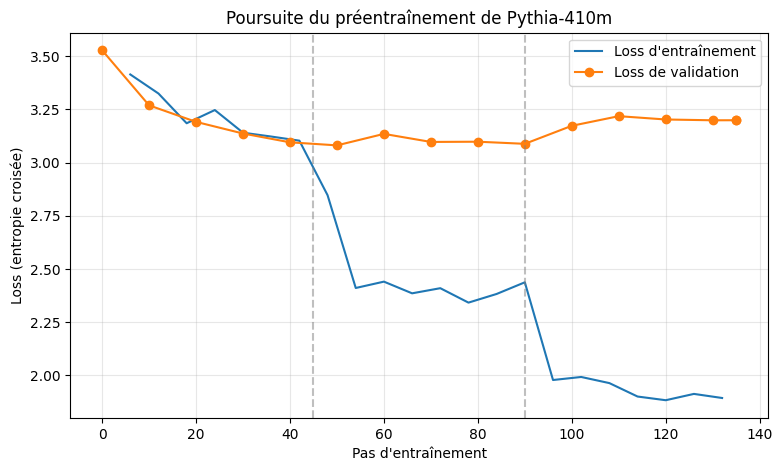

In [19]:
import matplotlib.pyplot as plt

historique = trainer.state.log_history

logs_train = [d for d in historique if "loss" in d]
logs_eval  = [d for d in historique if "eval_loss" in d]


steps_train = [d["step"] for d in logs_train]
loss_train  = [d["loss"] for d in logs_train]

loss_initiale = 3.5277
steps_eval = [0] + [d["step"] for d in logs_eval]
loss_eval  = [loss_initiale] + [d["eval_loss"] for d in logs_eval]


plt.figure(figsize=(9, 5))
plt.plot(steps_train, loss_train, label="Loss d'entraînement")
plt.plot(steps_eval, loss_eval, marker="o", label="Loss de validation")

for fin_epoque in [45, 90]:
    plt.axvline(fin_epoque, color="gray", linestyle="--", alpha=0.5)

plt.xlabel("Pas d'entraînement")
plt.ylabel("Loss (entropie croisée)")
plt.title("Poursuite du préentraînement de Pythia-410m")
plt.legend()
plt.grid(alpha=0.3)

plt.savefig("t2_courbe_loss.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Génération de réponses avec le nouveau modèle

In [20]:
test_fn = "data/test_questions.json"

In [21]:
import json
from tqdm.auto import tqdm

with open(test_fn, "r", encoding="utf-8") as f:
    test_data = json.load(f)
print(f"{len(test_data)} questions chargées")

model.eval()
results = []
for item in tqdm(test_data):
    generated = generate_answer(item["question"], model, tokenizer)
    results.append({
        "question": item["question"],
        "reference": item["answer"],
        "generated": generated,
    })

# Aperçu des 3 premières réponses
for r in results[:3]:
    print("Q :", r["question"])
    print("R :", r["generated"])
    print("-" * 80)

50 questions chargées


  0%|          | 0/50 [00:00<?, ?it/s]

Q : What is the context window size of GPT-3?
R : The context window size was set to 128K. This means that when a user opens an image, it will be shown in the context window with a maximum width of 128K and a height of 256K. When asked for more information about what images are displayed by GPT-3, OpenAI provided this answer: "The number of parameters used during training has not been disclosed". However, researchers have noted that while GPT-3's default configuration uses around 1 million parameters per model, some
--------------------------------------------------------------------------------
Q : Explain what is a transformer architecture.
R : A transformers are neural networks that can perform multiple tasks at the same time, by using different layers of neurons and their connections to other layers. They have been used in many areas including natural language processing (NLP), computer vision, audio generation, robotics, video games, and image recognition. The term "transformer" w

In [22]:
output_fn = "t2_answers.json"
with open(output_fn, "w", encoding="utf-8") as f:
    json.dump(results, f, ensure_ascii=False, indent=2)
print("Réponses sauvegardées dans", output_fn)

Réponses sauvegardées dans t2_answers.json


## 5. Évaluation des résultats

Vous pouvez réutiliser le code d'évaluation rendu disponible pour la tâche 1.

In [23]:
import string
import re
from collections import Counter

def remove_articles(text):
    return re.sub(r'\b(a|an|the)\b', ' ', text)

def white_space_fix(text):
    return ' '.join(text.split())

def remove_punc(text):
    exclude = set(string.punctuation)
    return ''.join(ch for ch in text if ch not in exclude)

def lower(text):
    return text.lower()

def normalize_answer(s):
    """Mettre en minuscule et retirer la ponctuation, des déterminants and les espaces."""
    return white_space_fix(remove_articles(remove_punc(lower(s))))

In [24]:
def evaluate_f1(ground_truth, prediction):
    """Normalise les 2 textes, trouve ce qu'il y a en commun et estime précision, rappel et F1."""
    prediction_tokens = normalize_answer(prediction).split()
    ground_truth_tokens = normalize_answer(ground_truth).split()
    common = Counter(prediction_tokens) & Counter(ground_truth_tokens)
    num_same = sum(common.values())
    if num_same == 0:
        return 0.0, 0.0, 0.0
    precision = 1.0 * num_same / len(prediction_tokens)
    recall = 1.0 * num_same / len(ground_truth_tokens)
    f1 = (2 * precision * recall) / (precision + recall)
    return precision, recall, f1

In [25]:
import pandas as pd

for r in results:
    p, rc, f1 = evaluate_f1(r["reference"], r["generated"])
    r["precision"], r["recall"], r["f1"] = p, rc, f1

df = pd.DataFrame(results)
pd.set_option("display.max_colwidth", 80)
df[["question", "generated", "precision", "recall", "f1"]]

,question,generated,precision,recall,f1
0,What is the context window size of GPT-3?,The context window size was set to 128K. This means that when a user opens a...,0.082192,0.750000,0.148148
1,Explain what is a transformer architecture.,A transformers are neural networks that can perform multiple tasks at the sa...,0.160000,0.545455,0.247423
2,Define what is a generative pre-trained transformer (GPT).,"GPTs are models that can generate text, but they do not have access to the u...",0.115385,0.300000,0.166667
3,Which sources comprise the weighted pre-training dataset for GPT-3?,The weights of the pre-trained transformer are computed using a large corpus...,0.027397,0.142857,0.045977
4,List the three main classes of language modelling tasks discussed in the con...,Transformers are used to model human-like AI agents. They have been applied ...,0.025641,0.222222,0.045977
5,What is knowledge distillation in the context of transformer models?,It's a technique used to train large language models by training them on exa...,0.120482,0.322581,0.175439
6,What is GPT-4 and who developed it?,"It was created by a team of researchers at Google Brain, led by Yann LeCun. ...",0.125000,0.529412,0.202247
7,In what year was GPT-4 released in ChatGPT?,"It is available today. The release date of GPT-4 was announced on April 20, ...",0.026667,0.285714,0.048780
8,Describe what is multimodal capability in the context of GPT-4?,"The model can process text, images and audio. It also has a built-in microph...",0.107143,0.346154,0.163636
9,On what date was GPT-4 training completed?,"The first version of GPT-4, released in February 2026. It is a fine-tuned ve...",0.028571,0.285714,0.051948


In [26]:
print("Moyennes sur", len(df), "questions")
print("="*25)
print(f"Précision : {df['precision'].mean():.3f}")
print(f"Rappel    : {df['recall'].mean():.3f}")
print(f"F1        : {df['f1'].mean():.3f}")

print("\n 3 meilleures réponses (F1)")
print("="*25)
for _, r in df.nlargest(3, "f1").iterrows():
    print(f"[F1={r['f1']:.2f}] Q : {r['question']}")
    print("   Réf :", r["reference"])
    print("   Gén :", r["generated"], "\n")

print("3 pires réponses (F1)")
print("="*25)
for _, r in df.nsmallest(3, "f1").iterrows():
    print(f"[F1={r['f1']:.2f}] Q : {r['question']}")
    print("   Réf :", r["reference"])
    print("   Gén :", r["generated"], "\n")

Moyennes sur 50 questions
Précision : 0.080
Rappel    : 0.296
F1        : 0.120

 3 meilleures réponses (F1)
[F1=0.32] Q : What does the term 'reinforcement learning' refer to in the context of DeepMind's early work?
   Réf : Reinforcement learning is an algorithm that learns from experience using only raw pixels as data input. DeepMind used this approach to train AI systems to play video games and board games by learning from the outcomes of their actions.
   Gén : Reinforcement Learning is a technique used by DeepMind and other AI researchers to train models. In reinforcement learning, an agent learns to choose actions based on previous experiences that it has acquired through interaction with the environment (the world). This process involves finding patterns in the data which help guide the agent towards desired outcomes. The goal of RLHF is to use this information to improve future decisions about how to act. For example, if the data shows humans are more likely to commit crimes t

Comparaison avec la tâche 1

In [27]:
# Réponses générées par le modèle d'origine
t1_fn = "data/t1_answers.json"
print("Fichier T1 trouvé :", os.path.exists(t1_fn))

with open(t1_fn, "r", encoding="utf-8") as f:
    results_t1 = json.load(f)

for r in results_t1:
    p, rc, f1 = evaluate_f1(r["reference"], r["generated"])
    r["precision"], r["recall"], r["f1"] = p, rc, f1

df_t1 = pd.DataFrame(results_t1)


assert list(df_t1["question"]) == list(df["question"]), "Les questions T1 et T2 ne correspondent pas!"
print(len(df_t1), "réponses T1 chargées")

Fichier T1 trouvé : True
50 réponses T1 chargées


In [28]:
# 1. Moyennes côte à côte
moyennes = pd.DataFrame({
    "T1 (sans adaptation)": df_t1[["precision", "recall", "f1"]].mean(),
    "T2 (préentraînement)": df[["precision", "recall", "f1"]].mean(),
})
moyennes["Différence"] = moyennes.iloc[:, 1] - moyennes.iloc[:, 0]
print("Moyennes sur", len(df), "questions")
print("=" * 25)
print(moyennes.round(3), "\n")

# 2. Différence de F1 question par question
df_comp = pd.DataFrame({
    "question":  df["question"],
    "reference": df["reference"],
    "gen_t1":    df_t1["generated"],
    "gen_t2":    df["generated"],
    "f1_t1":     df_t1["f1"],
    "f1_t2":     df["f1"],
})
df_comp["delta_f1"] = df_comp["f1_t2"] - df_comp["f1_t1"]

print("Questions améliorées :", (df_comp["delta_f1"] > 0).sum())
print("Questions dégradées  :", (df_comp["delta_f1"] < 0).sum())
print("Questions identiques :", (df_comp["delta_f1"] == 0).sum())


def afficher(lignes, titre):
    print("\n" + titre)
    print("=" * 25)
    for _, r in lignes.iterrows():
        print(f"[ΔF1={r['delta_f1']:+.2f}] Q : {r['question']}")
        print("   Réf :", r["reference"])
        print(f"   T1 (F1={r['f1_t1']:.2f}) :", r["gen_t1"])
        print(f"   T2 (F1={r['f1_t2']:.2f}) :", r["gen_t2"], "\n")

afficher(df_comp.nlargest(3, "delta_f1"),  "3 plus grandes progressions")
afficher(df_comp.nsmallest(3, "delta_f1"), "3 plus grandes régressions")

df_comp.to_csv("t2_comparaison_t1.csv", index=False)

Moyennes sur 50 questions
           T1 (sans adaptation)  T2 (préentraînement)  Différence
precision                 0.091                 0.080      -0.011
recall                    0.205                 0.296       0.091
f1                        0.107                 0.120       0.014 

Questions améliorées : 31
Questions dégradées  : 18
Questions identiques : 1

3 plus grandes progressions
[ΔF1=+0.15] Q : What is DeepSeek Harness and what license is it distributed under?
   Réf : DeepSeek Harness is an open-source AI agent harness developed by DeepSeek that provides an environment for building and running AI agents. It is distributed under the MIT License.
   T1 (F1=0.00) : It's a free software project. The code can be downloaded from the GitHub repository at https://github.com/DeepSeekHarness/. You will need to have an account on Github, or you'll get a warning message when trying to download your own version of the library. If you don't want to use this program, then just instal